In [1]:
import numpy as np 
from subprocess import check_output
import numpy as np
import laspy as lp
import matplotlib.pyplot as plt
from stl import mesh
import sys
import ezdxf
from os.path import normpath, exists
from base import spline
from base import simplify 
from base.centreline import Centerliner, Unzigzag, writeBinPath, writeDXFPath, runModule, readBinPath
from base.utils import find_neighbours_with_knn, return_rings

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# loop over all test cases, extract centreline and plot it.

In [2]:
basenames = ["straight_cylinder_L10_R1",
             "straight_elliptical_prism_L10_R1_R05",
             "straight_cylinder_L10_R_variable",
             "straight_cylinder_L8_R1_stochastic",
             "sinuous_D5_r_1",
             "extra_sinuous_D5_r_1"]
             #"Riesengang_subset"]

             #"vers_chez_le_brandt"]


#basenames = ["Archamps", "Lauiloch"]

In [10]:
rings = [] # store for plotting. 
meshes = [] # store for plotting. 

for c, basename in enumerate(basenames):

    CONDUIT_NAME = basename
    MODULE = "voxelize"
    MODULE_PATH = normpath(f"./base/{MODULE}.exe")
    CONDUIT_PATH = normpath(f"./data/{CONDUIT_NAME}.stl")
    OUTPUT_PATH = normpath(f"./data/voxsets/{CONDUIT_NAME}.vxl")
    DELTA = 200
    ADJACENT_TRIANGLES_PATH = f"./data/{basename}_adjacent_triangles.txt"


    # run the voxelizer module. 
    check_output(f"{MODULE_PATH} {DELTA} {CONDUIT_PATH} {OUTPUT_PATH}")

    # instantiate a Centerliner class using the output voxel set and delta.
    c = Centerliner(OUTPUT_PATH, DELTA)


    c.addEdges()

    # to look at the grid and clearance
    # c.writeEdges(f"{thedir}/edges.xyz")
    keep = True
    
    meshdata = mesh.Mesh.from_file(CONDUIT_PATH)

    meshes.append(meshdata.centroids[::20])

    if exists(ADJACENT_TRIANGLES_PATH) and keep:
        adjacent_triangles = np.loadtxt(ADJACENT_TRIANGLES_PATH).astype(int)
    else:
        adjacent_triangles = find_neighbours_with_knn(meshdata)
        np.savetxt(ADJACENT_TRIANGLES_PATH,adjacent_triangles, fmt="%.1d")

        
    out = return_rings(meshdata, adjacent_triangles)
    rings.append(out)

    source1 = c.findNearestNode(out["P1"]*1000)
    target1 = c.findNearestNode(out["P2"]*1000)

    p = c.computeCenterline(source1, target1)

    # writeDXFPath(f"{thedir}/rawpath.dxf", p)

    u = Unzigzag(p, c.G.nodes, c.delta)
    u.addEdges()
    p = u.shortestPath(source1, target1)

    p1 =[np.array(x) for x in p]

    coords = np.array(p1)/1000
    
    # save to file.
    np.savetxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_raw_centreline.txt", coords, fmt= "%.3e")

    thedir = "./temp/"
    # polygonal path
    writeDXFPath(f"{thedir}/centerline.dxf", p1)
    print(p1)
    # simplified polygonal path
    p2 = simplify.douglasPeucker(DELTA, p1)
    writeDXFPath(f"{thedir}/centerline-simplified.dxf", p2)

    coords = np.array(p2)/1000
    # save to file.
    np.savetxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerline-simplified.txt", coords, fmt= "%.3e")


    sys.stderr.write(f"Polyline has {len(p1)} vertices\n")
    sys.stderr.write(f"Simplified polyline has {len(p2)} vertices\n")

    # now fit cubic B-splines to p1 and p2
    writeBinPath(f"{thedir}/path.bin", p1)
    writeBinPath(f"{thedir}/path-simplified.bin", p2)

    runModule("./base/bspliner", [str(len(p1) / 3), f"{thedir}/path.bin", f"{thedir}/bspline.bin"])
    runModule("./base/bspliner", [str(len(p2) / 3), f"{thedir}/path.bin", f"{thedir}/bspline1.bin"])
    runModule(
        "./base/bspliner",
        [
            str(len(p2) / 3),
            f"{thedir}/path-simplified.bin",
            f"{thedir}/bspline-simplified.bin",
        ],
    )

    cps = readBinPath(f"{thedir}/bspline.bin")
    s1 = spline.bspline(cps)
    s2 = spline.subdivideBeziers(s1, 100)

    ps = [bezier[0] for bezier in s2]
    ps.append(s2[-1][-1])
    writeDXFPath(f"{thedir}/centerspline-fit.dxf", ps, ezdxf.colors.RED)

    if len(p2) > 2:

        # create B-spline directly from vertices of simplified path
        s3 = spline.bspline(p2)
        s4 = spline.subdivideBeziers(s3, 100)

        ps = [bezier[0] for bezier in s4]
        ps.append(s4[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-direct.dxf", ps, ezdxf.colors.GREEN)

        coords = np.array(ps)/1000
        # save to file.
        np.savetxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt", coords, fmt= "%.3e")


        cps = readBinPath(f"{thedir}/bspline-simplified.bin")
        s5 = spline.bspline(cps)
        s6 = spline.subdivideBeziers(s5, 100)

        ps = [bezier[0] for bezier in s6]
        ps.append(s6[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-fit-simplified.dxf", ps, ezdxf.colors.YELLOW)

        cps = readBinPath(f"{thedir}/bspline1.bin")
        s7 = spline.bspline(cps)
        s8 = spline.subdivideBeziers(s7, 100)

        ps = [bezier[0] for bezier in s8]
        ps.append(s8[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-fit1.dxf", ps, ezdxf.colors.WHITE)

        coords = np.array(ps)/1000
        # save to file.
        np.savetxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-fit1-simplified.txt", coords, fmt= "%.3e")
        
    else:
        print("simplified polyline has fewer than 2 vertices. Impossible to simplify further.")
        s4 = spline.subdivideBeziers(s2, 100)

        ps = [bezier[0] for bezier in s4]
        ps.append(s4[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-direct.dxf", ps, ezdxf.colors.GREEN)
        
        coords = np.array(ps)/1000
        # save to file.
        np.savetxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt", coords, fmt= "%.3e")


Read 'data\voxsets\straight_cylinder_L10_R1.vxl': 174,644 vertices and 3,722 grid points,
Added edges in 1.1 sec.


found ring 1 with 715 points.
found ring 2 with 715 points.


Computed maximum spanning tree for clearance in 0.0 sec.
Computed path in maximum spanning tree in 0.0 sec.


Added edges in 0.0 sec.
Computed shortest path in 0.0 sec.
[array([-4800,     0,     0]), array([-4600,     0,     0]), array([-4400,     0,     0]), array([-4200,     0,     0]), array([-4000,     0,     0]), array([-3800,     0,     0]), array([-3600,     0,     0]), array([-3400,     0,     0]), array([-3200,     0,     0]), array([-3000,     0,     0]), array([-2800,     0,     0]), array([-2600,     0,     0]), array([-2400,     0,     0]), array([-2200,     0,     0]), array([-2000,     0,     0]), array([-1800,     0,     0]), array([-1600,     0,     0]), array([-1400,     0,     0]), array([-1200,     0,     0]), array([-1000,     0,     0]), array([-800,    0,    0]), array([-600,    0,    0]), array([-400,    0,    0]), array([-200,    0,    0]), array([0, 0, 0]), array([200,   0,   0]), array([400,   0,   0]), array([600,   0,   0]), array([800,   0,   0]), array([1000,    0,    0]), array([1200,    0,    0]), array([1400,    0,    0]), array([1600,    0,    0]), array([180

Polyline has 50 vertices
Simplified polyline has 2 vertices


...

Polyline has 62 vertices
Simplified polyline has 12 vertices
Read 'data\voxsets\extra_sinuous_D5_r_1.vxl': 195,640 vertices and 6,300 grid points,
Added edges in 1.0 sec.


found ring 1 with 349 points.
found ring 2 with 274 points.


Computed maximum spanning tree for clearance in 0.1 sec.
Computed path in maximum spanning tree in 0.0 sec.


Added edges in 0.1 sec.
Computed shortest path in 0.0 sec.
[array([-5000,   200,     0]), array([-5000,   400,     0]), array([-5000,   600,     0]), array([-5000,   800,     0]), array([-5000,  1000,     0]), array([-5000,  1200,     0]), array([-5000,  1400,     0]), array([-5000,  1600,     0]), array([-5000,  1800,     0]), array([-5000,  2000,     0]), array([-5000,  2200,     0]), array([-5000,  2400,     0]), array([-5000,  2600,     0]), array([-4800,  2800,     0]), array([-4600,  3000,     0]), array([-4400,  3200,     0]), array([-4200,  3400,     0]), array([-4000,  3600,     0]), array([-3800,  3800,     0]), array([-3600,  4000,     0]), array([-3400,  4200,     0]), array([-3200,  4400,     0]), array([-3000,  4600,     0]), array([-2800,  4600,     0]), array([-2600,  4800,     0]), array([-2400,  4800,     0]), array([-2200,  4800,     0]), array([-2000,  4600,     0]), array([-1800,  4400,     0]), array([-1600,  4200,     0]), array([-1400,  4000,     0]), array([-12

Polyline has 102 vertices
Simplified polyline has 12 vertices


In [12]:
rings

[{'ring1': array([[-4.993736  , -0.06446261, -0.99611324],
         [-4.9937215 , -0.05254318, -0.99680424],
         [-4.9935346 ,  0.18368538, -0.98145866],
         ...,
         [-4.99311   ,  0.726278  , -0.68610907],
         [-4.992955  ,  0.9230787 , -0.38220358],
         [-4.992953  ,  0.92474556, -0.37784243]], dtype=float32),
  'P1': array([-4.9938855e+00,  1.1527328e-03,  1.4374227e-02], dtype=float32),
  'nP1': array([ 9.9999964e-01, -8.1522099e-04, -8.4298925e-05], dtype=float32),
  'ring2': array([[ 4.9945235 ,  0.247007  , -0.9655754 ],
         [ 4.994538  ,  0.23374379, -0.9684124 ],
         [ 4.994552  ,  0.2240154 , -0.97063273],
         ...,
         [ 4.995732  , -0.99876404,  0.04439227],
         [ 4.99543   , -0.68702936,  0.72405356],
         [ 4.9955163 , -0.77511334, -0.6298091 ]], dtype=float32),
  'P2': array([4.9949365e+00, 4.1379076e-03, 5.0646099e-03], dtype=float32),
  'nP2': array([-9.9999946e-01, -1.0354001e-03,  9.7861026e-05], dtype=float32)},


In [4]:
def plot_centrelines(basename_list,ids, out_fp, figsize =(8,6)):
    arrow_props = dict(zorder=100, scale=0.6, width= 0.01, scale_units= "x", alpha = 0.5)    

    fig = plt.figure(figsize = figsize)


    for c, (theid,  basename) in enumerate(zip(ids, basename_list)):
    
        CONDUIT_NAME = basename
        DELTA = 200

        meshdata = meshes[theid]
        ring = rings[theid]

        centreline = np.loadtxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_raw_centreline.txt")
        centrespline = np.loadtxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt")
        if exists(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-fit1-simplified.txt"):
            centrespline_fit = np.loadtxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-fit1-simplified.txt")
        else:
            centrespline_fit = np.loadtxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt")

        ax = fig.add_subplot(3, len(basename_list), c+1)
        ax.scatter(*meshdata[::10, [0,1]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*ring["ring1"][:, [0,1]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*ring["ring2"][:, [0,1]].T, c="C1", s = 2, label = "ring 2")
        ax.quiver(*ring["P1"][[0,1]] ,*ring["nP1"][[0,1]],color = "C0", **arrow_props)
        ax.quiver(*ring["P2"][[0,1]] ,*ring["nP2"][[0,1]],color = "C1", **arrow_props)
        ax.plot(*centreline[:, [0,1]].T, "-o", markersize=1, color = "k")
        ax.plot(*centrespline[:, [0,1]].T, "-o", markersize=1, color = "firebrick")
        ax.plot(*centrespline_fit[:, [0,1]].T, "-o", markersize=1, color = "deeppink")

        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
        ax.set_aspect("equal")


        ax = fig.add_subplot(3, len(basename_list), len(basename_list)+c+1)

        ax.scatter(*meshdata[::10, [0,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*ring["ring1"][:, [0,2]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*ring["ring2"][:, [0,2]].T, c="C1", s = 2, label = "ring 2")
        ax.quiver(*ring["P1"][[0,2]] ,*ring["nP1"][[0,2]],color = "C0", **arrow_props)
        ax.quiver(*ring["P2"][[0,2]] ,*ring["nP2"][[0,2]],color = "C1", **arrow_props)
        ax.plot(*centreline[:, [0,2]].T, "-o", markersize=1, color = "k")
        ax.plot(*centrespline[:, [0,2]].T, "-o", markersize=1, color = "firebrick")
        ax.plot(*centrespline_fit[:, [0,2]].T, "-o", markersize=1, color = "deeppink")

        ax.set_xlabel('X')
        ax.set_ylabel('Z')
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
        ax.set_aspect("equal")

        ax = fig.add_subplot(3, len(basename_list), 2*len(basename_list)+c+1)

        ax.scatter(*meshdata[::10, [1,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*ring["ring1"][:, [1,2]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*ring["ring2"][:, [1,2]].T, c="C1", s = 2, label = "ring 2")
        ax.plot(*centreline[:, [1,2]].T, "-o", markersize=1, color = "k")
        ax.plot(*centrespline[:, [1,2]].T, "-o", markersize=1, color = "firebrick")
        ax.plot(*centrespline_fit[:, [1,2]].T, "-o", markersize=1, color = "deeppink")

        ax.set_xlabel('X')
        ax.set_ylabel('Z')
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
        ax.set_aspect("equal")
        #ax.legend()
    
    plt.tight_layout()
    plt.savefig(out_fp, dpi = 300)
    plt.show()


In [5]:
basenames_simple = ["straight_cylinder_L10_R1",
             "straight_elliptical_prism_L10_R1_R05",
             "straight_cylinder_L10_R_variable"]

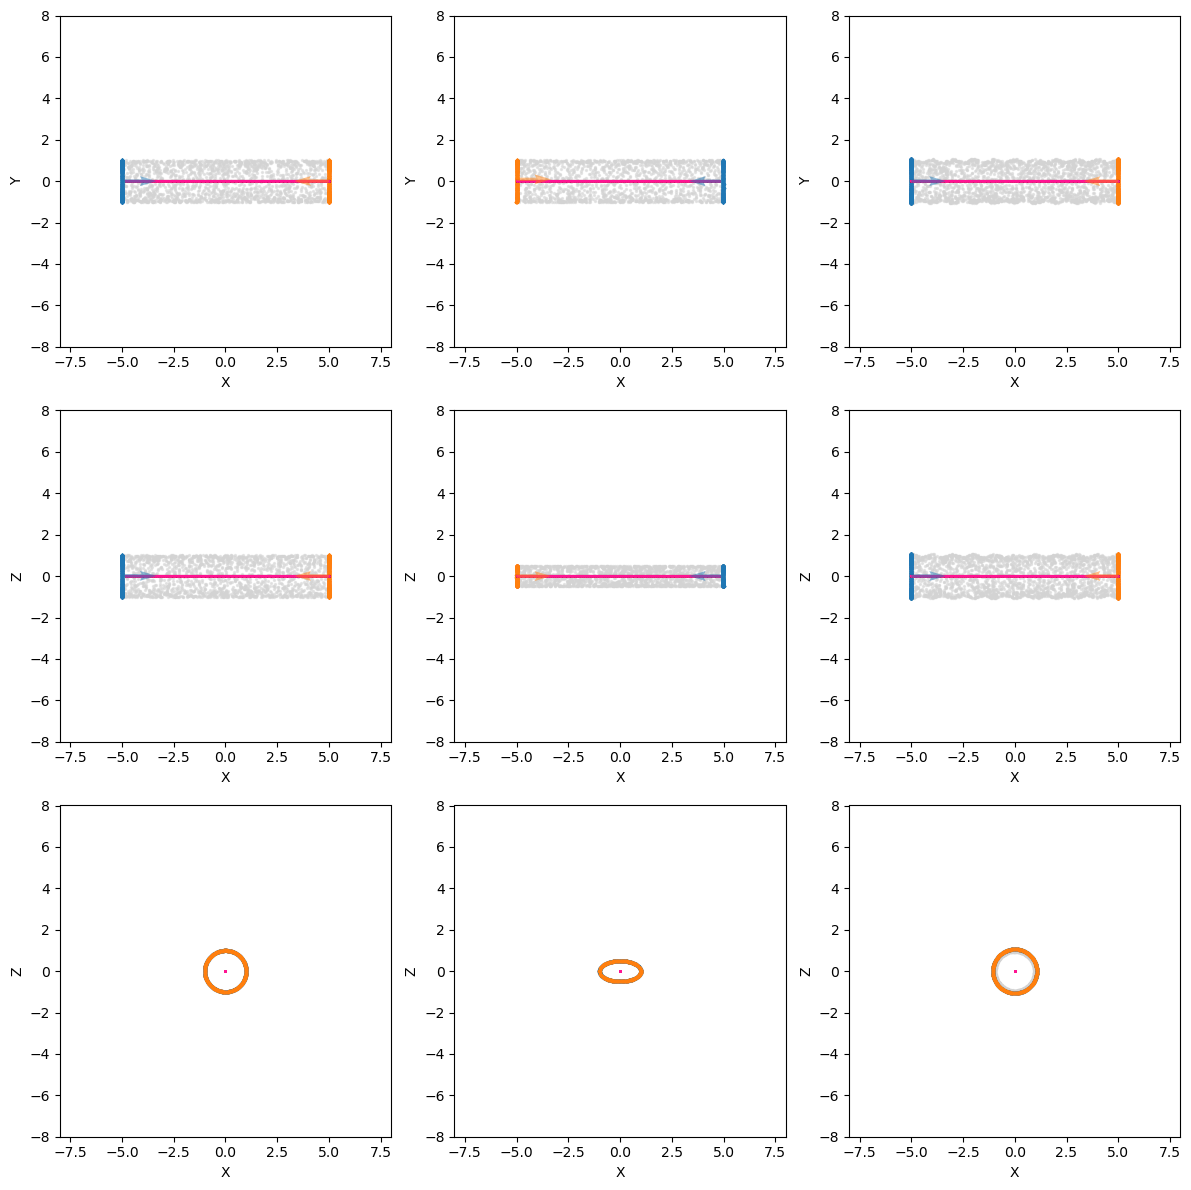

In [6]:
plot_centrelines(basenames_simple,[0,1,2], "./temp/finding_inlet_outlet_rings_and_centrelines_MST_simple.png", figsize=(12,12))

In [7]:
basenames_complex = ["straight_cylinder_L8_R1_stochastic","sinuous_D5_r_1","extra_sinuous_D5_r_1"]

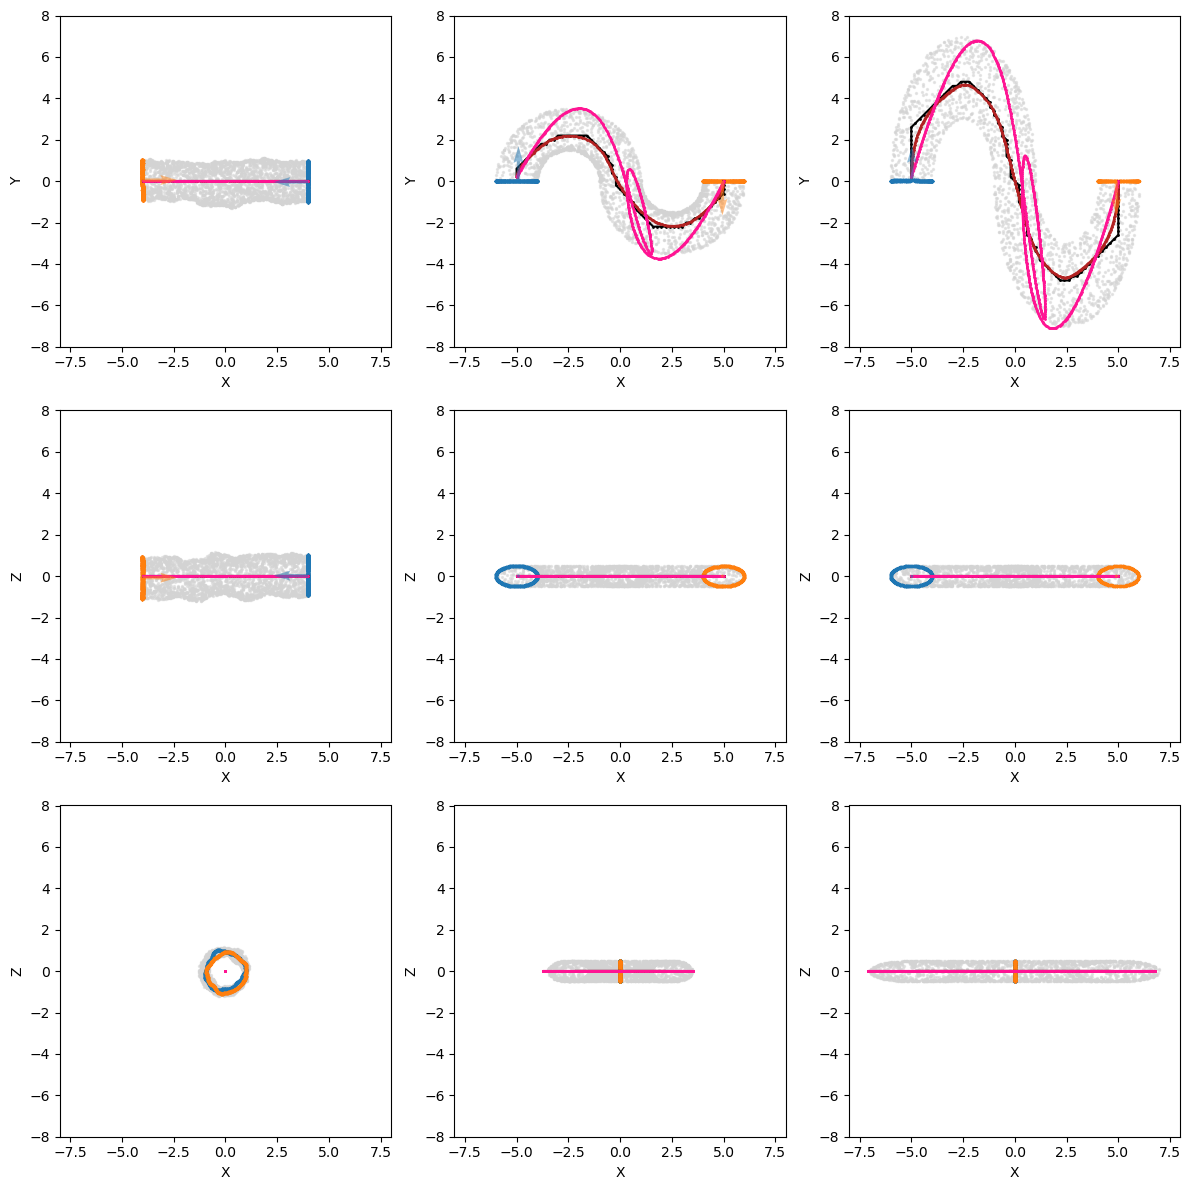

In [13]:
plot_centrelines(basenames_complex,[3,4,5], "./temp/finding_inlet_outlet_rings_and_centrelines_MST_complex_with_spline.png", figsize=(12,12))

In [25]:
def plot_a_centreline(basename,id,  out_fp, figsize = (6,6), loc = True):

    arrow_props = dict(zorder=100, scale=0.6, width= 0.01, scale_units= "x", alpha = 0.5)    

    fig = plt.figure(figsize = figsize)


    
    CONDUIT_NAME = basename
    DELTA = 200

    meshdata = meshes[id]
    ring = rings[id]

    centreline = np.loadtxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_raw_centreline.txt")
    centrespline = np.loadtxt(f"./temp/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt")
    
    ax = fig.add_subplot(3, 1, 1)
    ax.scatter(*meshdata[::10, [0,1]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*ring["ring1"][:, [0,1]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*ring["ring2"][:, [0,1]].T, c="C1", s = 2, label = "ring 2")
    ax.quiver(*ring["P1"][[0,1]] ,*ring["nP1"][[0,1]],color = "C0", **arrow_props)
    ax.quiver(*ring["P2"][[0,1]] ,*ring["nP2"][[0,1]],color = "C1", **arrow_props)
    ax.plot(*centreline[:, [0,1]].T, "-o", markersize=1, color = "k")
    ax.plot(*centrespline[:, [0,1]].T, "-o", markersize=1, color = "firebrick")

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    if loc != False:
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
    ax.set_aspect("equal")


    ax = fig.add_subplot(3, 1, 2)

    ax.scatter(*meshdata[::10, [0,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*ring["ring1"][:, [0,2]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*ring["ring2"][:, [0,2]].T, c="C1", s = 2, label = "ring 2")
    ax.quiver(*ring["P1"][[0,2]] ,*ring["nP1"][[0,2]],color = "C0", **arrow_props)
    ax.quiver(*ring["P2"][[0,2]] ,*ring["nP2"][[0,2]],color = "C1", **arrow_props)
    ax.plot(*centreline[:, [0,2]].T, "-o", markersize=1, color = "k")
    ax.plot(*centrespline[:, [0,2]].T, "-o", markersize=1, color = "firebrick")

    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    if loc != False:
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
    ax.set_aspect("equal")

    ax = fig.add_subplot(3, 1, 3)

    ax.scatter(*meshdata[::10, [1,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*ring["ring1"][:, [1,2]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*ring["ring2"][:, [1,2]].T, c="C1", s = 2, label = "ring 2")
    ax.plot(*centreline[:, [1,2]].T, "-o", markersize=1, color = "k")
    ax.plot(*centrespline[:, [1,2]].T, "-o", markersize=1, color = "firebrick")

    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    if loc != False:
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
    ax.set_aspect("equal")
    #ax.legend()

    plt.tight_layout()
    plt.savefig(out_fp, dpi = 300)
    plt.show()


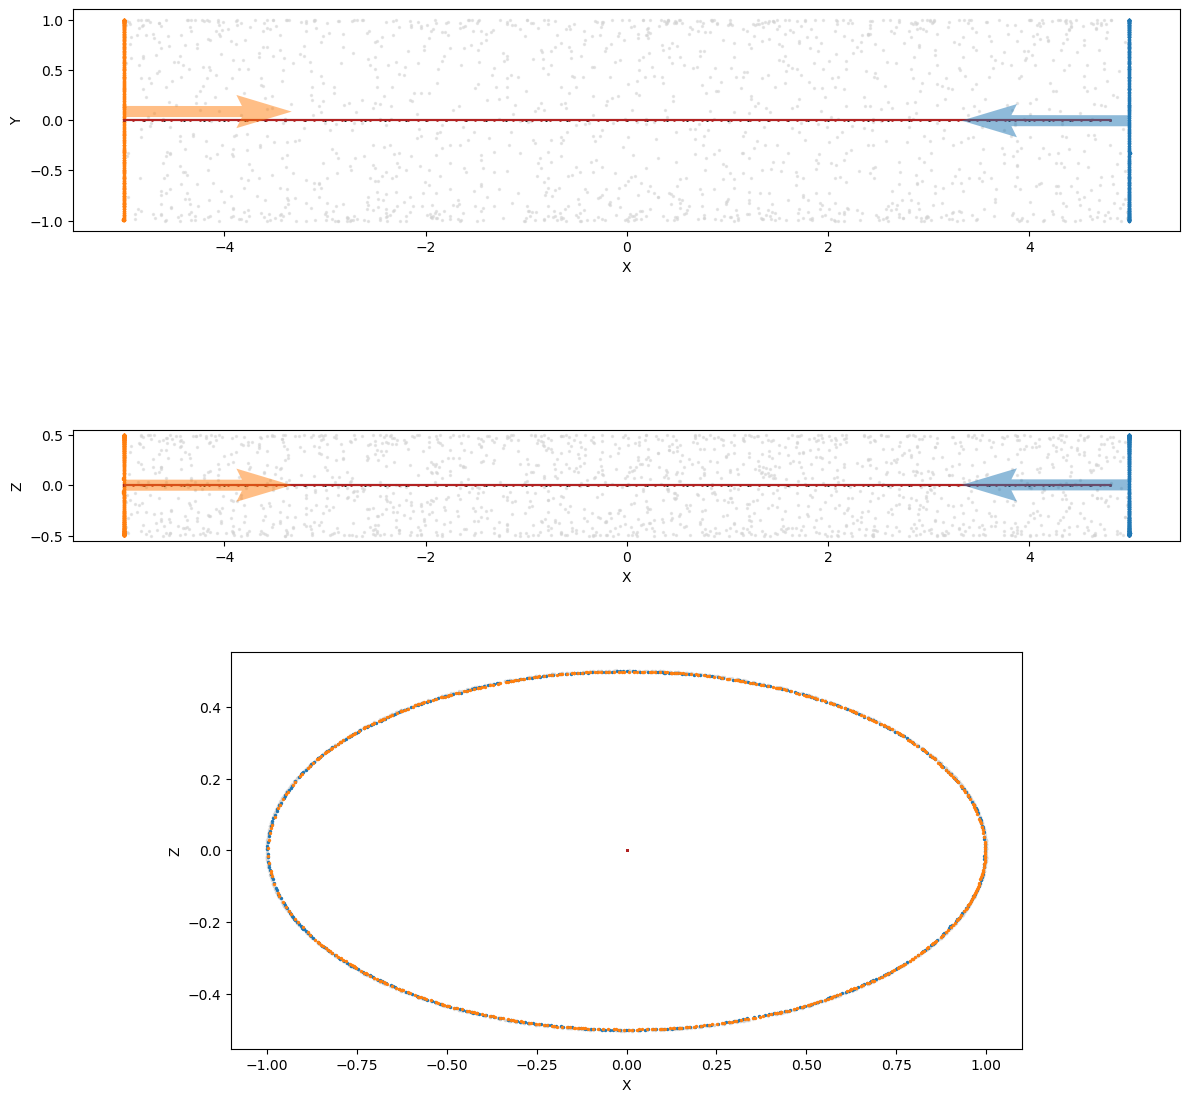

In [26]:
ID = 1

plot_a_centreline(basenames[ID], ID, 
                  f"./temp/finding_inlet_outlet_rings_and_centrelines_MST_{ID}.png",
                   figsize=(12,12), 
                   loc = False)